# Annulus mantle convection with four prescribed surface sectors

This notebook runs one 30 Ma Underworld3 mantle-annulus model. The outer circle is divided into four equal 90° sectors, with tangential surface velocities in increasing-angle order of +2, −2, +8, and −8 cm/yr. Positive is anticlockwise and negative is clockwise. Thus the four sectors contain the requested 2 cm/yr anticlockwise, 2 cm/yr clockwise, 8 cm/yr anticlockwise, and 8 cm/yr clockwise plate motions.

The velocities assigned to the sectors produce one-sided relative jumps of +10, −4, +10, and −16 cm/yr at 0°, 90°, 180°, and 270°. These jumps are listed in the parameter table. The continuous P2 finite-element solution interpolates locally at each shared sector junction; the plate interiors retain their prescribed speeds.

The initial temperature follows a piecewise-linear depth curve from 0 °C at the surface, with a small four-lobed perturbation. The mantle has the requested three depth-dependent viscosities. The annulus is coarse for this test, so the interpolated contour maps improve display smoothness without increasing solution resolution.

## 1. Install Underworld3 and start the notebook server

For a fresh Linux, macOS, or WSL installation, use Underworld3's official `./uw` setup. It installs Pixi if needed, configures a supported environment, installs prerequisites, and builds Underworld3:

```bash
git clone https://github.com/underworldcode/underworld3.git
cd underworld3
./uw setup
```

Choose **No AMR**, **Runtime**, and the platform-default MPI for this example, then accept the Underworld3 build. The Runtime environment includes JupyterLab and visualization dependencies. See the [official Quick Install](https://underworld3.readthedocs.io/en/latest/beginner/installation.html) for current options.

For the workspace used to create this notebook, the Underworld3 checkout is in a sibling `underworld3-runtime` directory. From the workspace root, run:

```bash
./underworld3-runtime/uw shell
```

To launch the notebook directly from the same workspace root:

```bash
./underworld3-runtime/uw jupyter lab annulus_mantle_convection.ipynb
```

If you cloned this example repository separately, use the `uw` wrapper from your Underworld3 checkout and give it the notebook's full path:

```bash
cd /path/to/underworld3
./uw jupyter lab /path/to/Underworld3_withChatGPT/annulus_mantle_convection.ipynb
```

The example repository does not vendor a second Underworld3 installation. The notebook should use the kernel provided by the Underworld3 Runtime environment.


In [1]:
# Confirm this is the Underworld3 Runtime kernel and import its bundled prerequisites.
import sys
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.interpolate import griddata
import underworld3 as uw
from IPython.display import HTML, display
from html import escape

print(f"Python: {sys.version.split()[0]}")
print(f"Underworld3: {getattr(uw, '__version__', 'version not exposed')}")
print(f"MPI ranks: {uw.mpi.size}")
print(f"Underworld3 module: {uw.__file__}")

def show_table(headers, rows, caption=None):
    """Display a small HTML table without adding a pandas dependency."""
    head = ''.join(f"<th>{escape(str(h))}</th>" for h in headers)
    body = ''.join(
        '<tr>' + ''.join(f"<td>{escape(str(value))}</td>" for value in row) + '</tr>'
        for row in rows
    )
    title = f"<caption>{escape(caption)}</caption>" if caption else ''
    display(HTML(
        '<table style="border-collapse:collapse; width:auto;">' + title +
        '<thead><tr>' + head + '</tr></thead><tbody>' + body + '</tbody></table>'
    ))


Python: 3.12.12
Underworld3: 0.0.0
MPI ranks: 1
Underworld3 module: /home/stuart/Documents/ChatGPT/Underworld3/underworld3-runtime/.pixi/envs/runtime/lib/python3.12/site-packages/underworld3/__init__.py


## 2. Equations and nondimensionalization

Let $\mathbf u$ be velocity, $p$ pressure, $T$ temperature normalized by 3000 °C, and $\eta$ viscosity normalized by $10^{21}\,\mathrm{Pa\,s}$. Underworld3’s native transient Navier–Stokes solver advances momentum, and its advection–diffusion solver transports temperature:

| Equation | Form used in the model |
|---|---|
| Navier–Stokes momentum | $Re[\partial_t\mathbf u+(\mathbf u\cdot\nabla)\mathbf u]-\nabla\cdot[2\eta\,\boldsymbol{\varepsilon}(\mathbf u)]+\nabla p=Ra\,D\,(T-T_{ref})\,\hat{\mathbf r}$ |
| Incompressibility | $\nabla\cdot\mathbf u=0$ |
| Heat transport | $\partial_t T+\mathbf u\cdot\nabla T=D\nabla^2T$, solved with `uw.systems.AdvDiffusion` (Eulerian SUPG BDF2, $\theta=1$) |
| Strain rate | $\boldsymbol{\varepsilon}(\mathbf u)=(\nabla\mathbf u+\nabla\mathbf u^T)/2$ |
| Outer plate motion | $u_r=0$; $u_\theta=(+2,-2,+8,-8)$ cm/yr on successive 90° sectors; positive is anticlockwise |

Lengths are scaled by mantle thickness $L=2891\,\mathrm{km}$, viscosity by $\eta_0=10^{21}\,\mathrm{Pa\,s}$, temperature by 3000 °C, and time by $t_0=1$ Ma. The velocity scale is $L/t_0=289.1\,\mathrm{cm/yr}$. For mantle density $\rho=3300\,\mathrm{kg/m^3}$, the dimensionless inertia coefficient is $Re=\rho L^2/(\eta_0t_0)\approx8.7\times10^{-19}$. Momentum therefore adjusts far faster than the geological timestep, and mantle flow remains Stokes-like even though the transient Navier–Stokes solve runs every timestep. With $\kappa=10^{-6}\,\mathrm{m^2/s}$, thermal diffusivity is $D=\kappa t_0/L^2=3.78\times10^{-6}$. The buoyancy coefficient is $RaD$ for $Ra=10^4$, with temperature anomaly measured from the prescribed radial reference geotherm.


## 3. Parameters and prescribed model states

The initial geotherm is a simple reference curve: 0 °C at the surface, 1300 °C at 100 km, 1600 °C at 660 km, and 3000 °C at the CMB, interpolated linearly between knots. It is not a detailed mineral-physics adiabat. The initial thermal perturbation has a peak amplitude of 30 °C and is tapered to zero at both radial boundaries. Buoyancy uses the temperature anomaly from the reference depth curve.

The outer boundary has one four-sector velocity pattern, not separate speed cases. Its values are +2, −2, +8, and −8 cm/yr in successive 90° sectors. Because sector speeds differ in magnitude, the resulting junction jumps are not all 2 or 8 cm/yr; the table below gives each actual one-sided jump.

In [2]:
# Physical reference values and dimensionless model parameters.
YEAR_S = 365.25 * 24 * 3600
MA_S = 1.0e6 * YEAR_S
L_M = 2891.0e3
R_OUT_M = 6371.0e3
R_IN_M = 3480.0e3
ETA_REF = 1.0e21  # Pa s
RHO_MANTLE = 3300.0  # kg/m^3
REYNOLDS = RHO_MANTLE * L_M**2 / (ETA_REF * MA_S)  # dimensionless inertia coefficient
KAPPA = 1.0e-6    # m^2/s
T_REF_C = 3000.0
DURATION_MA = 30.0
MAX_STEP_MA = 0.5
CELL_SIZE_ND = 0.12
REFINEMENT_LEVELS = 0
RAYLEIGH = 1.0e4  # standard thermal Rayleigh number; reduced smoke-test value
VELOCITY_UNIT_CM_PER_YR = L_M / MA_S * YEAR_S * 100.0
DIFFUSIVITY_ND = KAPPA * MA_S / L_M**2
BUOYANCY_ND = RAYLEIGH * DIFFUSIVITY_ND

GEOTHERM_DEPTH_KM = np.array([0.0, 100.0, 660.0, 2891.0])
GEOTHERM_TEMP_C = np.array([0.0, 1300.0, 1600.0, 3000.0])
SURFACE_SECTOR_VELOCITIES_CM_YR = np.array([2.0, -2.0, 8.0, -8.0])  # CCW positive, sectors 0–90–180–270–360°

parameter_rows = [
    ("Geometry", "Outer radius", f"{R_OUT_M/1000:.0f} km", "Earth surface radius"),
    ("Geometry", "Inner radius", f"{R_IN_M/1000:.0f} km", "CMB radius"),
    ("Geometry", "Mantle thickness / length scale", f"{L_M/1000:.0f} km", "All coordinates scaled by L"),
    ("Mesh", "Target cell size", f"{CELL_SIZE_ND:g} L, no uniform refinement", "Coarse test mesh"),
    ("Mesh", "Velocity / pressure / temperature degree", "2 / 1 / 2", "Finite-element polynomial degree"),
    ("Solver", "Velocity preconditioner", "GAMG", "Explicit for the single-level coarse test mesh"),
    ("Rheology", "Reference viscosity", f"{ETA_REF:.1e} Pa s", "Viscosity scale"),
    ("Rheology", "Lithosphere", "1e22 Pa s", "0–100 km depth"),
    ("Rheology", "Asthenosphere", "1e19 Pa s", "100–660 km depth"),
    ("Rheology", "Lower mantle", "1e21 Pa s", "660–2891 km depth"),
    ("Thermal", "Diffusivity / time scheme", f"{KAPPA:.1e} m²/s; Eulerian SUPG BDF2, θ=1", f"D = {DIFFUSIVITY_ND:.3e}; SUPG stabilization on fixed mesh"),
    ("Thermal", "Temperature scale / boundary temperatures", "3000 °C / 0 °C surface / 3000 °C CMB", "Temperature stored as T/3000 °C"),
    ("Thermal", "Initial geotherm knots", "0 km: 0 °C; 100 km: 1300 °C; 660 km: 1600 °C; 2891 km: 3000 °C", "Piecewise linear with 30 °C tapered perturbation"),
    ("Forcing", "Thermal Rayleigh / Navier–Stokes coefficients", f"Ra={RAYLEIGH:.1e}; Ra·D={BUOYANCY_ND:.3e}; Re={REYNOLDS:.3e}", "Ma time scale; physical inertia from 3300 kg/m³ mantle density"),
    ("Forcing", "Four sector tangential velocities", "+2, −2, +8, −8 cm/yr", "Successive 90° sectors; + is anticlockwise"),
    ("Run", "Duration / maximum time step", f"{DURATION_MA:g} / {MAX_STEP_MA:g} Ma", "One combined model; final step hits 30 Ma"),
    ("Boundaries", "Inner velocity", "No-slip", "Both velocity components zero"),
    ("Boundaries", "Outer velocity", "Prescribed tangential; zero normal", "Fixed annulus; no mesh motion"),
]
show_table(("Group", "Parameter", "Value", "Definition"), parameter_rows, "Model parameters")

# Compute one-sided jumps in the direction of increasing angle.
boundary_angles_deg = [0, 90, 180, 270]
incoming_speeds = np.roll(SURFACE_SECTOR_VELOCITIES_CM_YR, 1)
outgoing_speeds = SURFACE_SECTOR_VELOCITIES_CM_YR
boundary_rows = []
for angle, incoming, outgoing in zip(boundary_angles_deg, incoming_speeds, outgoing_speeds):
    jump = outgoing - incoming
    junction_type = "Divergent" if jump > 0 else "Convergent"
    boundary_rows.append((
        f"{angle}°",
        junction_type,
        f"{incoming:+g} → {outgoing:+g} cm/yr",
        f"{jump:+g} cm/yr",
    ))
show_table(
    ("Boundary angle", "Junction", "Incoming → outgoing uθ", "Signed Δuθ"),
    boundary_rows,
    "One-sided velocity jumps implied by the four sector speeds",
)
print(f"Velocity scale: {VELOCITY_UNIT_CM_PER_YR:.1f} cm/yr; D = {DIFFUSIVITY_ND:.3e}; Navier–Stokes coefficients Re = {REYNOLDS:.3e}; buoyancy Ra·D = {BUOYANCY_ND:.3e}")


Group,Parameter,Value,Definition
Geometry,Outer radius,6371 km,Earth surface radius
Geometry,Inner radius,3480 km,CMB radius
Geometry,Mantle thickness / length scale,2891 km,All coordinates scaled by L
Mesh,Target cell size,"0.12 L, no uniform refinement",Coarse test mesh
Mesh,Velocity / pressure / temperature degree,2 / 1 / 2,Finite-element polynomial degree
Solver,Velocity preconditioner,GAMG,Explicit for the single-level coarse test mesh
Rheology,Reference viscosity,1.0e+21 Pa s,Viscosity scale
Rheology,Lithosphere,1e22 Pa s,0–100 km depth
Rheology,Asthenosphere,1e19 Pa s,100–660 km depth
Rheology,Lower mantle,1e21 Pa s,660–2891 km depth


Boundary angle,Junction,Incoming → outgoing uθ,Signed Δuθ
0°,Divergent,-8 → +2 cm/yr,+10 cm/yr
90°,Convergent,+2 → -2 cm/yr,-4 cm/yr
180°,Divergent,-2 → +8 cm/yr,+10 cm/yr
270°,Convergent,+8 → -8 cm/yr,-16 cm/yr


Velocity scale: 289.1 cm/yr; D = 3.776e-06; Navier–Stokes coefficients Re = 8.740e-19; buoyancy Ra·D = 3.776e-02


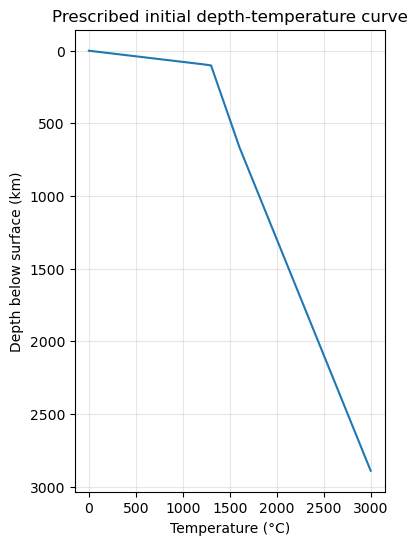

In [3]:
# The initial radial temperature profile, before the angular perturbation.
depth_plot_km = np.linspace(0, L_M / 1000, 400)
plt.figure(figsize=(4, 6))
plt.plot(np.interp(depth_plot_km, GEOTHERM_DEPTH_KM, GEOTHERM_TEMP_C), depth_plot_km)
plt.gca().invert_yaxis()
plt.xlabel("Temperature (°C)")
plt.ylabel("Depth below surface (km)")
plt.title("Prescribed initial depth-temperature curve")
plt.grid(True, alpha=0.3)
plt.show()


## 4. Build the model and run it

The coarse, single-level mesh has no geometric hierarchy, so the notebook explicitly selects the algebraic multigrid (`gamg`) velocity preconditioner; this avoids a fallback warning. For a refined production mesh, use at least one uniform refinement level and set `preconditioner="auto"` to allow Underworld3 to select geometric multigrid.

At every 0.5 Ma step, `uw.systems.NavierStokes` solves momentum from the current temperature, then `uw.systems.AdvDiffusion` advects and diffuses temperature with the updated velocity. The fixed outer boundary is impermeable and carries the four sector velocities (+2, −2, +8, −8) cm/yr. The initial mantle velocity is zero; the plate motion is applied in the first Navier–Stokes solve. The P2 velocity space is continuous, so the step changes interpolate locally at their shared junction nodes.

In [4]:
def run_case(sector_velocities_cm_yr, duration_ma=DURATION_MA, cell_size=CELL_SIZE_ND):
    # Scale radii by mantle thickness; depth is ro - r in these units.
    r_out = R_OUT_M / L_M
    r_in = R_IN_M / L_M
    mesh = uw.meshing.Annulus(
        radiusOuter=r_out,
        radiusInner=r_in,
        cellSize=cell_size,
        refinement=(REFINEMENT_LEVELS if REFINEMENT_LEVELS > 0 else None),
        qdegree=3,
    )
    x, y = mesh.CoordinateSystem.X
    r, theta = mesh.CoordinateSystem.xR
    radial = mesh.CoordinateSystem.unit_e_0
    tangent = mesh.CoordinateSystem.unit_e_1
    depth_nd = r_out - r
    depth_km = depth_nd * L_M / 1000.0
    # Same piecewise-linear depth curve used for initialization and the tables.
    reference_geotherm_nd = sp.Piecewise(
        (13.0 * depth_km / T_REF_C, depth_km <= 100.0),
        ((1300.0 + (300.0 / 560.0) * (depth_km - 100.0)) / T_REF_C, depth_km <= 660.0),
        ((1600.0 + (1400.0 / 2231.0) * (depth_km - 660.0)) / T_REF_C, True),
    )

    velocity = uw.discretisation.MeshVariable("v", mesh, 2, degree=2)
    pressure = uw.discretisation.MeshVariable("p", mesh, 1, degree=1, continuous=True)
    temperature = uw.discretisation.MeshVariable("T", mesh, 1, degree=2, continuous=True)

    # Temperature is dimensionless (0 to 1 = 0 to 3000 °C).
    temp_coords = np.asarray(temperature.coords)
    radius_at_nodes = np.sqrt(temp_coords[:, 0]**2 + temp_coords[:, 1]**2)
    depth_km_at_nodes = (r_out - radius_at_nodes) * L_M / 1000.0
    angular = np.arctan2(temp_coords[:, 1], temp_coords[:, 0])
    base_temp = np.interp(depth_km_at_nodes, GEOTHERM_DEPTH_KM, GEOTHERM_TEMP_C)
    perturbation = (
        0.01 * T_REF_C * np.sin(2.0 * angular)
        * np.sin(np.pi * np.clip(depth_km_at_nodes / (L_M / 1000.0), 0.0, 1.0))
    )
    initial_temperature = np.clip((base_temp + perturbation) / T_REF_C, 0.0, 1.0)
    temperature.array[...] = initial_temperature.reshape(temperature.array.shape)

    # Start from rest; each prescribed sector speed is dimensionalized for the solver.
    sector_velocities_cm_yr = np.asarray(sector_velocities_cm_yr, dtype=float)
    if sector_velocities_cm_yr.shape != (4,):
        raise ValueError("Provide one tangential speed for each of the four sectors.")
    sector_velocities_nd = sector_velocities_cm_yr / VELOCITY_UNIT_CM_PER_YR
    velocity.array[...] = 0.0

    # Piecewise constant viscosity by depth (dimensionless, eta_ref = 1e21 Pa s).
    eta_lith = 10.0
    eta_asth = 0.01
    eta_lower = 1.0
    eta_expr = sp.Piecewise(
        (eta_lith, depth_nd <= 100.0e3 / L_M),
        (eta_asth, depth_nd <= 660.0e3 / L_M),
        (eta_lower, True),
    )

    navier_stokes = uw.systems.NavierStokes(
        mesh, velocityField=velocity, pressureField=pressure,
        rho=REYNOLDS, order=2, advection="extrapolated", verbose=False,
    )
    # This single-level smoke-test mesh has no geometric hierarchy, so select GAMG explicitly.
    # A refined production mesh can use preconditioner="auto" to select geometric FMG.
    navier_stokes.preconditioner = "gamg"
    navier_stokes.constitutive_model = uw.constitutive_models.ViscousFlowModel
    navier_stokes.constitutive_model.Parameters.shear_viscosity_0 = eta_expr
    navier_stokes.bodyforce = BUOYANCY_ND * (temperature.sym[0] - reference_geotherm_nd) * radial
    navier_stokes.petsc_options["fieldsplit_velocity_mg_coarse_pc_type"] = "svd"

    # One constant tangential velocity per quadrant. Positive tangent is CCW.
    # Half-open inequalities assign shared axis nodes deterministically.
    sector_speed = sp.Piecewise(
        (float(sector_velocities_nd[0]), sp.And(x > 0.0, y >= 0.0)),
        (float(sector_velocities_nd[1]), sp.And(x <= 0.0, y > 0.0)),
        (float(sector_velocities_nd[2]), sp.And(x < 0.0, y <= 0.0)),
        (float(sector_velocities_nd[3]), True),
    )
    outer_velocity = sector_speed * tangent
    navier_stokes.add_dirichlet_bc(outer_velocity, "Upper")
    navier_stokes.add_dirichlet_bc((0.0, 0.0), "Lower")

    adv_diff = uw.systems.AdvDiffusion(
        mesh, u_Field=temperature, V_fn=velocity, order=2, theta=1.0, verbose=False
    )
    adv_diff.constitutive_model = uw.constitutive_models.DiffusionModel
    adv_diff.constitutive_model.Parameters.diffusivity = DIFFUSIVITY_ND
    adv_diff.add_dirichlet_bc(1.0, "Lower")
    adv_diff.add_dirichlet_bc(0.0, "Upper")

    def summarize(label, elapsed_ma):
        vel = np.asarray(velocity.array)
        temp_c = np.asarray(temperature.array[:, 0]) * T_REF_C
        vmag_cm_yr = np.linalg.norm(vel, axis=1) * VELOCITY_UNIT_CM_PER_YR
        return {
            "State": label,
            "Time (Ma)": elapsed_ma,
            "T min (°C)": round(float(np.min(temp_c)), 2),
            "T mean (°C)": round(float(np.mean(temp_c)), 2),
            "T max (°C)": round(float(np.max(temp_c)), 2),
            "|u| mean (cm/yr)": round(float(np.mean(vmag_cm_yr)), 3),
            "Max |u| all DOFs (cm/yr)": round(float(np.max(vmag_cm_yr)), 3),
        }

    states = [summarize("Initial", 0.0)]
    elapsed = 0.0
    step = 0
    while elapsed < duration_ma - 1.0e-10:
        dt = min(MAX_STEP_MA, duration_ma - elapsed)
        # Solve momentum from T_n, then transport T with the updated velocity u_(n+1).
        navier_stokes.solve(timestep=dt, zero_init_guess=False, verbose=False)
        adv_diff.solve(timestep=dt, zero_init_guess=False, verbose=False)
        elapsed += dt
        step += 1
        total_steps = int(np.ceil(duration_ma / MAX_STEP_MA))
        if step % 10 == 0 or step == total_steps:
            print(f"Navier-Stokes + temperature solve, step {step:02d}/{total_steps}, t={elapsed:.2f} Ma")

    states.append(summarize("Final", elapsed))
    return mesh, velocity, temperature, states


## 5. Run the 30 Ma test simulation

The combined model uses one coarse annulus mesh (cell size 0.12 L, no uniform refinement) and a maximum 0.5 Ma step. Each of its 60 steps performs one native Underworld3 Navier–Stokes solve followed by one Eulerian SUPG BDF2 temperature solve. The sector velocities are +2, −2, +8, and −8 cm/yr. Progress is reported after every coupled step. This is a computational test; scientific use requires resolution and timestep convergence checks.

In [5]:
sector_velocities_cm_yr = SURFACE_SECTOR_VELOCITIES_CM_YR.copy()
print(f"Running one 30 Ma model with sector velocities {sector_velocities_cm_yr.tolist()} cm/yr")
mesh, velocity, temperature, states = run_case(sector_velocities_cm_yr, duration_ma=DURATION_MA)
case_results = {
    "combined": {
        "mesh": mesh,
        "velocity": velocity,
        "temperature": temperature,
        "states": states,
        "sector_velocities_cm_yr": sector_velocities_cm_yr,
    }
}
show_table(
    ("State", "Time (Ma)", "T min (°C)", "T mean (°C)", "T max (°C)", "|u| mean (cm/yr)", "Max |u| all DOFs (cm/yr)"),
    [[row[k] for k in ("State", "Time (Ma)", "T min (°C)", "T mean (°C)", "T max (°C)", "|u| mean (cm/yr)", "Max |u| all DOFs (cm/yr)")] for row in states],
)

Running one 30 Ma model with sector velocities [2.0, -2.0, 8.0, -8.0] cm/yr
Navier-Stokes + temperature solve, step 10/60, t=5.00 Ma
Navier-Stokes + temperature solve, step 20/60, t=10.00 Ma
Navier-Stokes + temperature solve, step 30/60, t=15.00 Ma
Navier-Stokes + temperature solve, step 40/60, t=20.00 Ma
Navier-Stokes + temperature solve, step 50/60, t=25.00 Ma
Navier-Stokes + temperature solve, step 60/60, t=30.00 Ma


State,Time (Ma),T min (°C),T mean (°C),T max (°C),|u| mean (cm/yr),Max |u| all DOFs (cm/yr)
Initial,0.0,0.0,1924.69,3000.0,0.0,0.0
Final,30.0,0.0,1914.65,3000.0,1.03,32.584


## 6. Initial and final state table

These nodal statistics come from the one combined model. The initial velocity is zero by construction; the first Navier–Stokes step applies the four prescribed sector velocities. The maximum-speed column is the maximum over all velocity degrees of freedom in the mantle domain, not a surface-only value. The prescribed surface sectors have a peak absolute speed of 8 cm/yr; buoyancy-driven interior flow can exceed that.

In [6]:
state_rows = []
sector_label = ", ".join(f"{speed:+g}" for speed in SURFACE_SECTOR_VELOCITIES_CM_YR)
for state in states:
    state_rows.append([
        sector_label,
        state["State"],
        state["Time (Ma)"],
        state["T min (°C)"],
        state["T mean (°C)"],
        state["T max (°C)"],
        state["|u| mean (cm/yr)"],
        state["Max |u| all DOFs (cm/yr)"],
    ])
show_table(
    ("Sector uθ (cm/yr), CCW positive", "State", "Time (Ma)", "T min (°C)", "T mean (°C)", "T max (°C)", "|u| mean (cm/yr)", "Max |u| all DOFs (cm/yr)"),
    state_rows,
    "Initial and final states for the combined model",
)

"Sector uθ (cm/yr), CCW positive",State,Time (Ma),T min (°C),T mean (°C),T max (°C),|u| mean (cm/yr),Max |u| all DOFs (cm/yr)
"+2, -2, +8, -8",Initial,0.0,0.0,1924.69,3000.0,0.0,0.0
"+2, -2, +8, -8",Final,30.0,0.0,1914.65,3000.0,1.03,32.584


## 7. Continuous field displays

The 30 Ma temperature and speed fields are linearly interpolated onto a fine plotting grid and masked to the circular annulus. This removes the polygonal appearance of the coarse mesh in the figure; it does not refine or alter the solved fields. The boundary-velocity plot remains piecewise constant to show the four prescribed plate speeds.

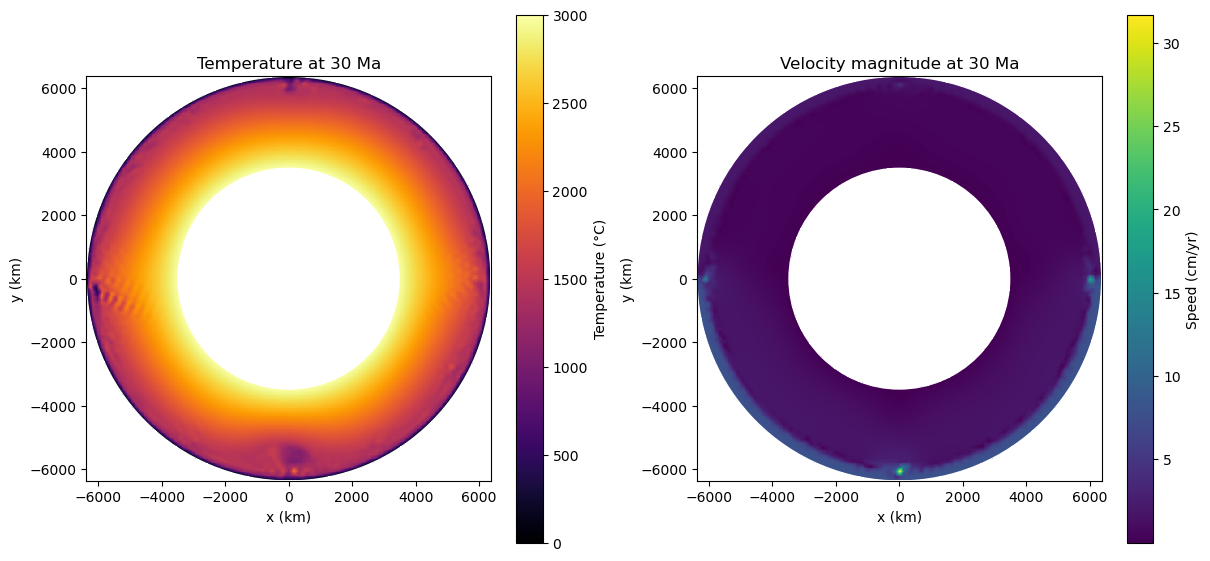

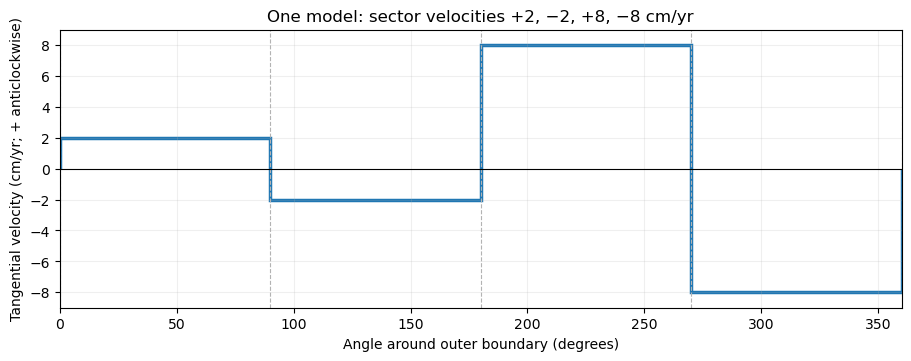

In [7]:
from matplotlib.patches import Circle

result = case_results["combined"]
res = 500
extent_km = R_OUT_M / 1000.0
grid_axis = np.linspace(-extent_km, extent_km, res)
grid_x, grid_y = np.meshgrid(grid_axis, grid_axis)
radius_grid = np.hypot(grid_x, grid_y)
inside_annulus = (radius_grid >= R_IN_M / 1000.0) & (radius_grid <= extent_km)

# Interpolate the solved nodal fields onto a fine Cartesian grid for display.
# This smooths visual faceting only; it does not change the finite-element solution.
temp_points_km = np.asarray(result["temperature"].coords) * (L_M / 1000.0)
temp_values_c = np.asarray(result["temperature"].array[:, 0]).reshape(-1) * T_REF_C
temp_grid = griddata(temp_points_km, temp_values_c, (grid_x, grid_y), method="linear")
temp_grid = np.ma.masked_where(~inside_annulus, temp_grid)

velocity_points_km = np.asarray(result["velocity"].coords) * (L_M / 1000.0)
velocity_dofs = np.asarray(result["velocity"].array)
velocity_dofs = velocity_dofs.reshape(velocity_dofs.shape[0], -1)
velocity_values_cm_yr = np.linalg.norm(velocity_dofs, axis=1) * VELOCITY_UNIT_CM_PER_YR
speed_grid = griddata(velocity_points_km, velocity_values_cm_yr, (grid_x, grid_y), method="linear")
speed_grid = np.ma.masked_where(~inside_annulus, speed_grid)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)
temp_plot = axes[0].pcolormesh(
    grid_x, grid_y, temp_grid, shading="auto", cmap="inferno",
    vmin=min(0.0, float(np.nanmin(temp_grid))), vmax=T_REF_C,
)
axes[0].set_title("Temperature at 30 Ma")
speed_plot = axes[1].pcolormesh(
    grid_x, grid_y, speed_grid, shading="auto", cmap="viridis",
)
axes[1].set_title("Velocity magnitude at 30 Ma")
for ax in axes:
    ax.add_patch(Circle((0, 0), R_IN_M / 1000.0, fill=False, color="white", linewidth=0.8))
    ax.add_patch(Circle((0, 0), extent_km, fill=False, color="white", linewidth=0.8))
    ax.set_aspect("equal")
    ax.set_xlim(-extent_km, extent_km)
    ax.set_ylim(-extent_km, extent_km)
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
fig.colorbar(temp_plot, ax=axes[0], label="Temperature (°C)")
fig.colorbar(speed_plot, ax=axes[1], label="Speed (cm/yr)")
plt.show()

# Keep the boundary profile piecewise constant to show the prescribed plate speeds.
sector_edges_deg = np.array([0, 90, 180, 270, 360])
fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
ax.stairs(SURFACE_SECTOR_VELOCITIES_CM_YR, sector_edges_deg, linewidth=2.5)
for angle in sector_edges_deg:
    ax.axvline(angle, color="0.7", linewidth=0.8, linestyle="--")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    xlim=(0, 360), ylim=(-9, 9),
    xlabel="Angle around outer boundary (degrees)",
    ylabel="Tangential velocity (cm/yr; + anticlockwise)",
    title="One model: sector velocities +2, −2, +8, −8 cm/yr",
)
ax.grid(alpha=0.2)
plt.show()

## 8. Interpretation, limitations, and references

- The single model prescribes sector velocities of +2, −2, +8, and −8 cm/yr in increasing angular order; positive is anticlockwise. Its one-sided jumps at 0°, 90°, 180°, and 270° are +10, −4, +10, and −16 cm/yr. The jumps follow directly from the four sector speeds.
- The outer boundary has zero normal velocity and the inner boundary is no-slip. Both boundaries are stationary in the mesh; there is no moving free surface.
- The field maps use linear interpolation onto a fine grid to remove visible polygonal facets. This is display interpolation only; the model still uses the coarse finite-element mesh stated in the parameter table.
- The initial geotherm and three viscosity layers are idealized. Native `uw.systems.NavierStokes` advances momentum every 0.5 Ma, followed by `uw.systems.AdvDiffusion` for temperature; both use Eulerian SUPG BDF2 on the fixed mesh. The dimensionless inertia coefficient is about 8.7 × 10⁻¹⁹, so velocity is quasi-steady on geological timesteps. The Rayleigh number is reduced for this test calculation.
- The coarse mesh can produce unphysical temperature undershoot near sharp gradients. Do not interpret temperature extrema as physical until the mesh and timestep are refined and boundedness is checked.
- The coarse mesh has no multigrid hierarchy, so Underworld3 reports a fallback to GAMG. This is a test calculation, not a validation benchmark.

### References

- [Underworld3 Quick Install](https://underworld3.readthedocs.io/en/latest/beginner/installation.html)
- [Underworld3 Eulerian SUPG Navier–Stokes guide](https://underworld3.readthedocs.io/en/latest/advanced/eulerian-navier-stokes.html)
- [Underworld3 Eulerian SUPG advection-diffusion guide](https://underworld3.readthedocs.io/en/latest/advanced/eulerian-advection-diffusion.html)
- [Underworld3 coupled convection tutorial](https://underworld3.readthedocs.io/en/latest/beginner/tutorials/8-Timestepping-coupled.html)
- [Underworld3 annulus mesh API](https://underworld3.readthedocs.io/en/latest/api/meshing.html)